# TicoShop Customer Churn Prediction & Segmentation

Customer segmentation (K-Means) and churn prediction (Decision Tree) for retail retention strategy.


In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset from local data directory (update path if running in Google Colab)
clientes = pd.read_excel("../data/TicoShop_Clientes.xlsx", sheet_name=0)

print("--- PRIMERAS FILAS ---")
display(clientes.head())

print("\n--- MEDIANA POR ESTADO DE DESERCIÓN ---")
clientes.groupby('se_fue').median(numeric_only=True)


 Selecciona el archivo: 


Saving TicoShop_Clientes.xlsx to TicoShop_Clientes (9).xlsx
--- PRIMERAS FILAS ---


,cliente_id,recencia,frecuencia,monto,antiguedad_meses,quejas,usa_app,se_fue
0,C0001,26,10,217500,35,0,0,0
1,C0002,33,5,346900,5,0,1,0
2,C0003,54,8,212800,29,0,0,0
3,C0004,17,2,116800,1,0,0,0
4,C0005,62,10,118300,40,0,0,0



--- SE APLICA LA MEDIANA ---


,recencia,frecuencia,monto,antiguedad_meses,quejas,usa_app
se_fue,,,,,,
0,24.0,7.0,205050.0,23.0,0.0,1.0
1,132.0,3.0,53800.0,28.0,1.0,0.0


# 1) Explore los datos y describa qué características distinguen a los clientes que dejaron de comprar de los que se quedaron.

Para conocer los datos de una mejor manera y evitar valores atípicos, se aplicó la mediana a todas las columnas. Con esto, se puede decir que los usuarios activos muestran una mejor recencia con un valor de 24 en comparación con los 132 que se fueron. Esto significa que los clientes que se fueron eran mucho menos activos y rentables, ya que compraban menos de 3 veces al año y gastaban un monto de ₡53 800, en comparación con los clientes que se quedaron, los cuales compran 7 veces al año y gastan ₡205 050. Otra característica es que los clientes que se van llevan 28 meses de antigüedad, en comparación con los 23 meses de los que se quedan, lo que quiere decir que los clientes más antiguos no están siendo retenidos.

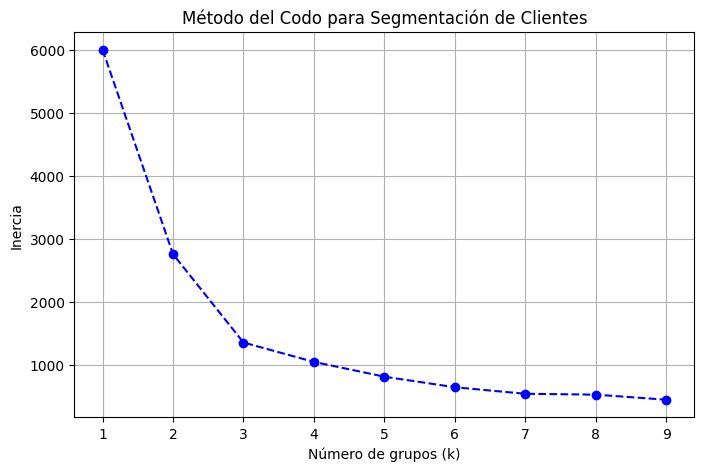

In [45]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

#Se realiza la segmentación en donde se asigna mediante un diccionario el nombre que tendrá cada grupo
nombres_segmentos = {0: 'Clientes Regulares', 1: 'Clientes Premium', 2: 'Clientes Inactivos'}
segmentacion = clientes[['recencia', 'frecuencia', 'monto']]
scaler = StandardScaler()
clientes_escalados = scaler.fit_transform(segmentacion)
km = KMeans(n_clusters=3, random_state=42)
clientes['grupo'] = km.fit_predict(clientes_escalados)
clientes['grupo'] = clientes['grupo'].map(nombres_segmentos)
clientes.groupby('grupo')[['recencia', 'frecuencia', 'monto']].median()


#Se implementa el grafico para el metodo del codo para poder respaldar las 3 segmentaciones que se hicieron
inercia = []
rango_k = range(1, 10)
for k in rango_k:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(clientes_escalados)
    inercia.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(rango_k, inercia, marker='o', linestyle='--', color='b')
plt.title('Método del Codo para Segmentación de Clientes')
plt.xlabel('Número de grupos (k)')
plt.ylabel('Inercia')
plt.grid(True)
plt.show()


# 2) Agrupe a los clientes en segmentos que tengan sentido para el negocio, póngale un nombre a cada uno y explique cómo es cada segmento.

Se segmentaron los clientes asignando un nombre que los identifique fácilmente según los resultados obtenidos al aplicar el método del codo, el cual muestra que en K hay 3-4 grupos claros y para este caso la mejor opción es segmentarlos en 3 grupos. En donde al grupo con los mejores valores se le nombró "Clientes Premium", al grupo con un comportamiento de compra normal como "Clientes Regulares". Como caso contrario, el grupo que lleva muchos meses sin comprar, con una frecuencia y monto bajo, se le nombró "Clientes Inactivos".



--- ÁRBOL DE DECISIONES ---


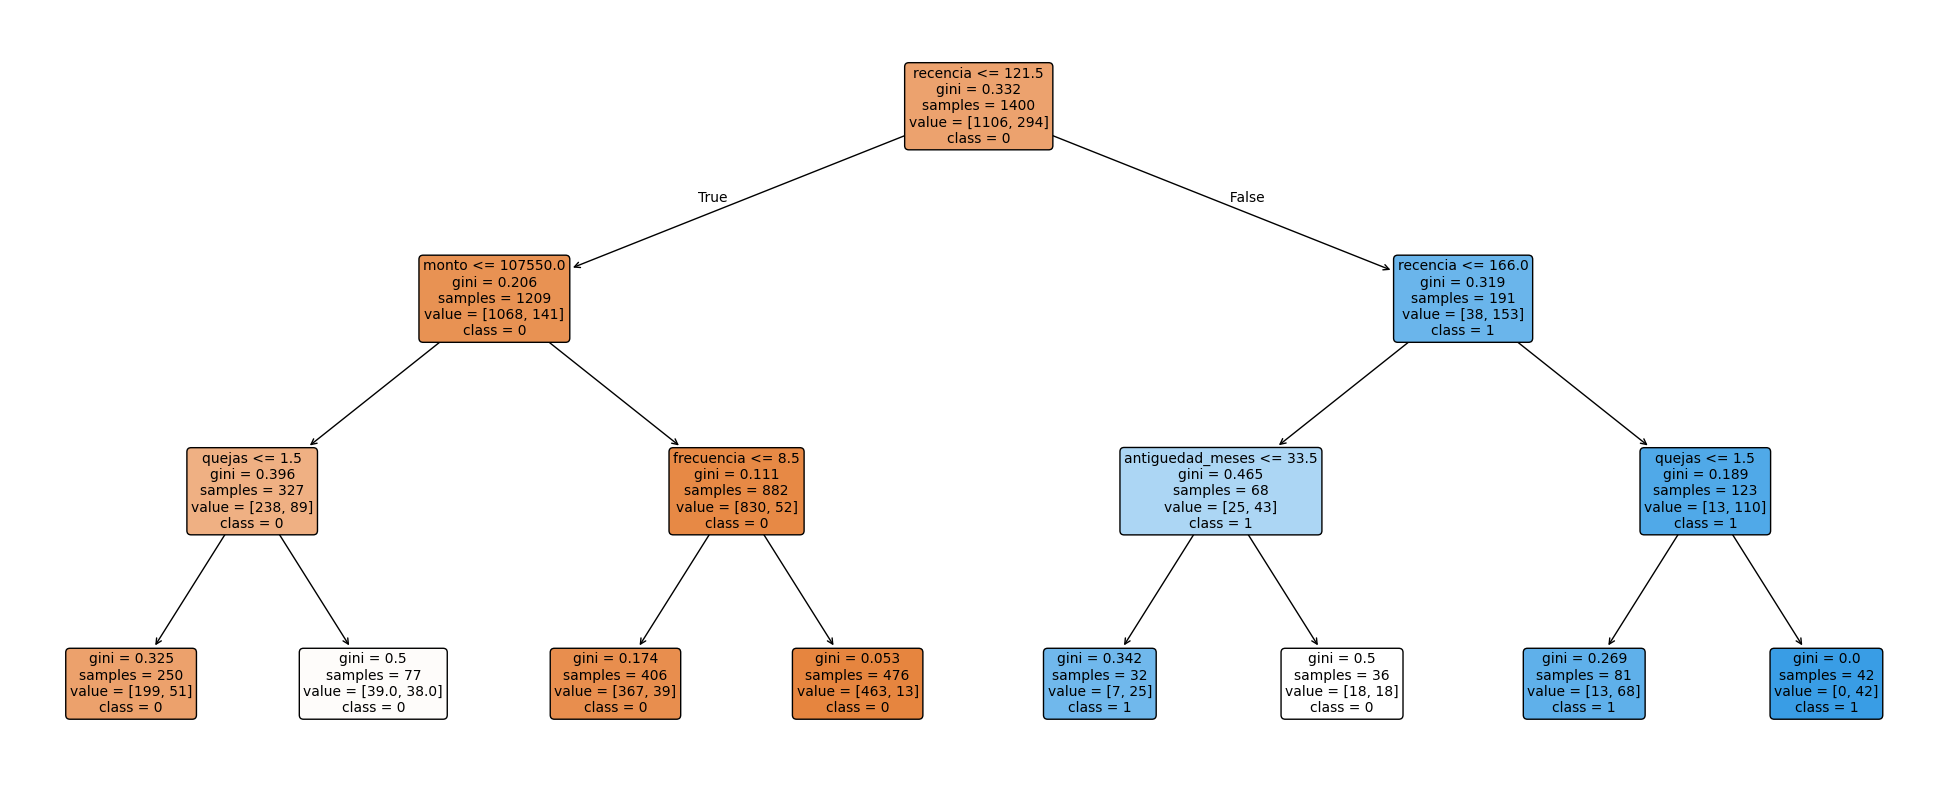



--- EVALUACIÓN DEL MODELO ---
Total de datos de prueba evaluados: 600
Exactitud del modelo: 86.17%




In [46]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

#Se define X y Y
x = clientes[["recencia", "frecuencia", "monto", "antiguedad_meses", "quejas", "usa_app"]]
y = clientes["se_fue"]

#Dividir entrenamiento y prueba
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)
modelo = DecisionTreeClassifier(max_depth=3, random_state=42)
modelo.fit(x_train, y_train)

print("\n")
print("--- ÁRBOL DE DECISIONES ---")
plt.figure(figsize=(25, 10))
plot_tree(modelo, feature_names=x.columns, class_names=[str(c) for c in modelo.classes_],filled=True, rounded=True,fontsize=10)
plt.show()

predicciones = modelo.predict(x_test)
exactitud = accuracy_score(y_test, predicciones)
print("\n")
print("--- EVALUACIÓN DEL MODELO ---")
print(f"Total de datos de prueba evaluados: {len(x_test)}")
print(f"Exactitud del modelo: {exactitud * 100:.2f}%")
print("\n")

# 3) Construya al menos un modelo que prediga qué clientes van a dejar de comprar y evalúe qué tan útil sería para la empresa.

Se implementó el modelo de árbol de decisión, ya que para este caso es necesario aplicar un modelo de clasificación para poder predecir cuando un cliente se va. Este modelo tiene una precisión de 86.17%, utilizando 70% de los datos para entrenar y 30% para pruebas, con esto TicoShop podría identificar rápidamente a los clientes que están a punto de dejar de comprar y con esto aplicar acciones o estrategias de mercadeo y retención.

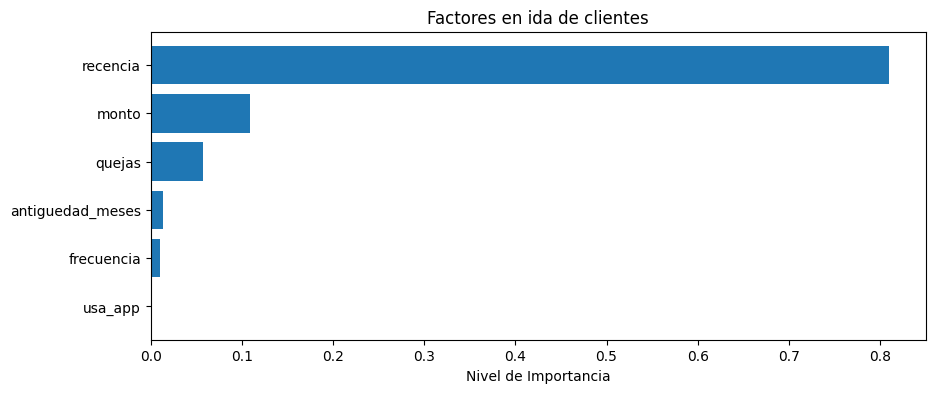

In [47]:
#Se extraen la información de las variables que el árbol aprendió, para luego graficarlo en un gráfico de barras
importancias = modelo.feature_importances_
factores = x.columns

#Se crea un dataframe para almacenar los datos del árbol y ordenarlos de mayor a menor importancia
df = pd.DataFrame({'Factor': factores, 'Importancia': importancias})
df = df.sort_values(by='Importancia', ascending=False)

plt.figure(figsize=(10, 4))
plt.barh(df['Factor'], df['Importancia'])
plt.gca().invert_yaxis()
plt.title('Factores en ida de clientes')
plt.xlabel('Nivel de Importancia')
plt.show()

# 4) Identifique qué factores aumentan o disminuyen el riesgo de que un cliente se vaya y explique qué significan para TicoShop

Gracias al modelo predictivo, podemos identificar de manera rápida los principales factores que provocan que un cliente se vaya. Como factor principal se encuentra la recencia, la cual indica que en TicoShop no se está logrando incentivar a los clientes para que vuelvan a comprar, siendo esta la razón de mayor peso del problema.

# 5) Proponga un plan de acción para la gerente de mercadeo: a qué clientes contactar primero, con qué estrategia y por qué. Escríbalo sin términos técnicos.

Principalmente se debe dar prioridad a los clientes que fueron identificados como clientes premium y clientes regulares, ya que estos son los clientes más importantes para TicoShop, por esta razón es necesario monitorearlos para saber cuando empiezan a mostrar señales de que se puedan ir. Se pueden implementar campañas orientadas a la retención, ofreciendo beneficios por tiempo limitado, ofrecer a este tipo de clientes puntos por sus compras para luego ser canjeados por productos seleccionados o descuentos en la compra total, en donde se le solicite sus datos personales que permitirían rastrear de manera más eficiente patrones y otros datos relevantes, además de que se podrían enviar correos electrónicos o mensajes ofreciendo descuentos o promociones de tiempo limitado. Esto se justifica porque el análisis realizado demostró que el paso del tiempo o inactividad de los clientes es la principal causa por la que se iban. Por esta razón al crear diversos canales que permitan contactar a los clientes con incentivos, ayudará a retenerlos. También por esta razón es que se tiene como prioridad enfocarse primero en los clientes que más gastan, ya que garantiza que la campaña sea altamente rentable para TicoShop.
